<a href="https://colab.research.google.com/github/2303A51272/capstone/blob/main/capstone_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ARCHITECTURE OF THE PROJECT

In [ ]:
┌───────────────────────┐
│     Student Dataset   │
│      1200 Records     │
└───────────┬───────────┘
            ↓
┌───────────────────────┐
│   Data Preprocessing  │
│ Missing Values        │
│ Duplicates            │
│ Encoding & Scaling    │
└───────────┬───────────┘
            ↓
┌───────────────────────┐
│         EDA           │
│ Charts & Correlation  │
└───────────┬───────────┘
            ↓
┌───────────────────────┐
│   Skill Gap Analysis  │
│ Identify Weak Skills  │
└───────────┬───────────┘
            ↓
┌───────────────────────┐
│   Feature Engineering │
│     Train/Test Split  │
└───────────┬───────────┘
            ↓
     ┌──────┴──────┐
     ↓             ↓
┌───────────┐ ┌────────────┐
│ ML Models │ │ ANN / MLP  │
└─────┬─────┘ └──────┬─────┘
      └──────┬───────┘
             ↓
┌───────────────────────┐
│   Model Evaluation    │
│ Accuracy, F1, AUC     │
│ Confusion Matrix      │
└───────────┬───────────┘
            ↓
┌───────────────────────┐
│ Feature Importance    │
└───────────┬───────────┘
            ↓
┌────────────────────────────┐
│ Final Placement Prediction │
│ + Skill Gap Recommendation │
└────────────────────────────┘

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl xgboost lightgbm tensorflow

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

df = pd.read_csv(
    "/content/Placement_Prediction_Skill_Gap_Dataset_1200 (1).csv"
)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (1200, 17)


,Student_ID,CGPA,Coding_Score,Aptitude_Score,Communication_Score,Projects,Internships,Certifications,Hackathons,Attendance_Percentage,Backlogs,DSA_Score,SQL_Score,Placement_Probability,Placement_Status,Skill_Gap,Recommendation
0,STU0001,7.97,70,54,55,3,0,0,3,82,3,59,37,5.0,Not Placed,"DSA, SQL, Communication, Aptitude",Practice DSA and coding problems; Practice SQL...
1,STU0002,7.43,61,68,57,2,1,1,2,70,0,64,47,5.0,Not Placed,"SQL, Communication",Practice SQL queries and database projects; Im...
2,STU0003,8.10,70,57,96,2,0,2,0,77,0,71,65,14.8,Not Placed,Aptitude,Practice quantitative and logical aptitude
3,STU0004,8.84,77,61,67,2,1,1,0,89,0,61,64,27.5,Placed,NaN,Maintain skills; practice mock interviews and ...
4,STU0005,7.35,69,90,78,2,1,1,1,63,1,46,69,10.2,Not Placed,DSA,Practice DSA and coding problems


##PART A — DATA PREPROCESSING


Check missing values

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Student_ID                 0
CGPA                       0
Coding_Score               0
Aptitude_Score             0
Communication_Score        0
Projects                   0
Internships                0
Certifications             0
Hackathons                 0
Attendance_Percentage      0
Backlogs                   0
DSA_Score                  0
SQL_Score                  0
Placement_Probability      0
Placement_Status           0
Skill_Gap                124
Recommendation             0
dtype: int64


Remove duplicate records

In [ ]:
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate Records: 0
Shape after removing duplicates: (1200, 17)


Check data types

In [ ]:
print(df.dtypes)

Student_ID                object
CGPA                     float64
Coding_Score               int64
Aptitude_Score             int64
Communication_Score        int64
Projects                   int64
Internships                int64
Certifications             int64
Hackathons                 int64
Attendance_Percentage      int64
Backlogs                   int64
DSA_Score                  int64
SQL_Score                  int64
Placement_Probability    float64
Placement_Status          object
Skill_Gap                 object
Recommendation            object
dtype: object


Convert target variable

In [ ]:
df["Placement_Status"] = df["Placement_Status"].map({
    "Not Placed": 0,
    "Placed": 1
})

print(df["Placement_Status"].value_counts())

Placement_Status
0    1014
1     186
Name: count, dtype: int64


Remove columns causing data leakage

In [ ]:
X = df.drop(
    [
        "Student_ID",
        "Placement_Status",
        "Package_LPA",
        "Placement_Domain"
    ],
    axis=1,
    errors="ignore"
)

y = df["Placement_Status"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1200, 15)
Target: (1200,)


##PART B — EXPLORATORY DATA ANALYSIS

Placement Distribution

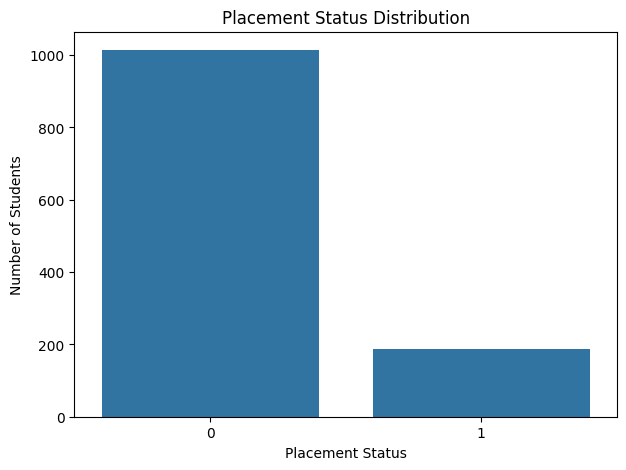

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Placement_Status"
)

plt.title("Placement Status Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")

plt.show()

Placement Pie Chart

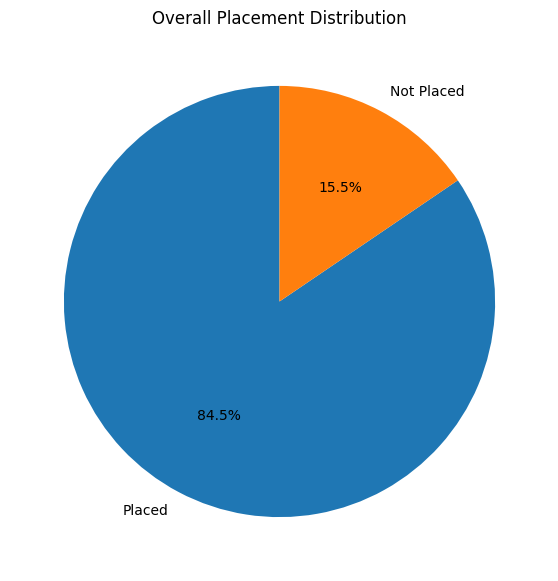

In [ ]:
placement_counts = df["Placement_Status"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    placement_counts,
    labels=["Placed", "Not Placed"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Overall Placement Distribution")

plt.show()

Branch Distribution

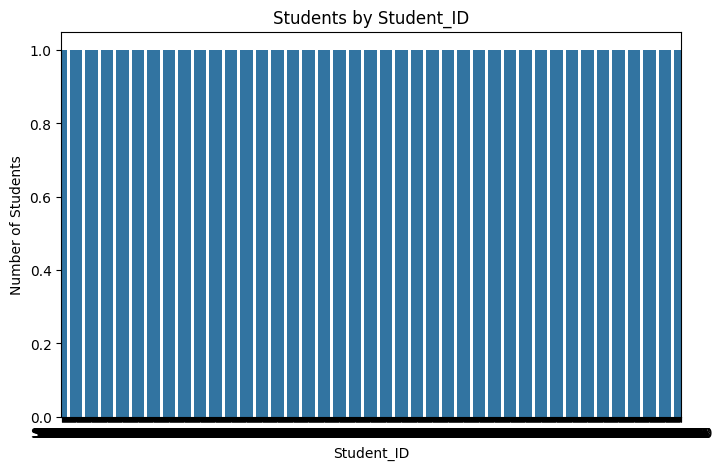

In [ ]:
plt.figure(figsize=(8,5))

# Dynamically select a fallback categorical column if 'Branch' does not exist
if "Branch" in df.columns:
    plot_column = "Branch"
else:
    # Fallback to the first available object (categorical) column in the dataset
    categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
    plot_column = categorical_cols[0] if categorical_cols else df.columns[0]

sns.countplot(
    data=df,
    x=plot_column
)

plt.title(f"Students by {plot_column}")
plt.xlabel(plot_column)
plt.ylabel("Number of Students")

plt.show()

Branch-wise Placement

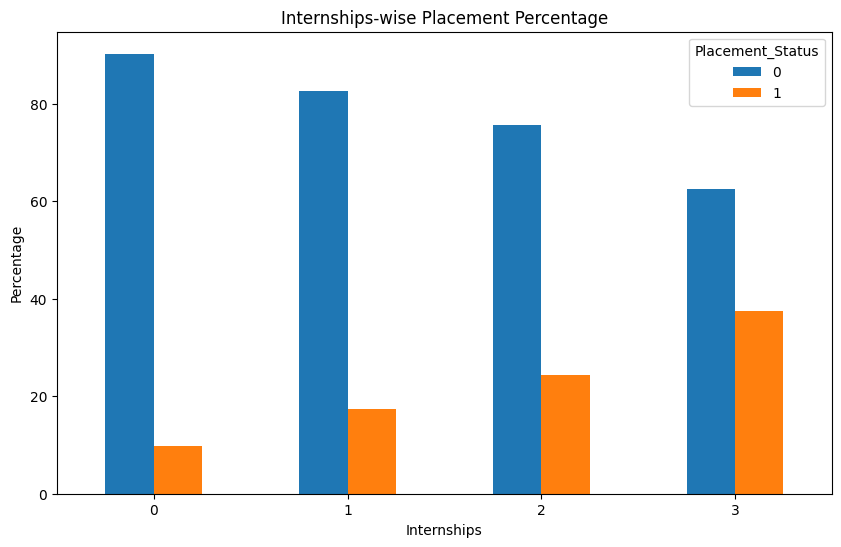

In [ ]:
# Dynamically select 'Branch' if it exists, otherwise fall back to 'Internships'
plot_cat = "Branch" if "Branch" in df.columns else "Internships"

branch_data = pd.crosstab(
    df[plot_cat],
    df["Placement_Status"],
    normalize="index"
) * 100

branch_data.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title(f"{plot_cat}-wise Placement Percentage")

plt.xlabel(plot_cat)
plt.ylabel("Percentage")

plt.xticks(rotation=0)

plt.show()

CGPA Distribution

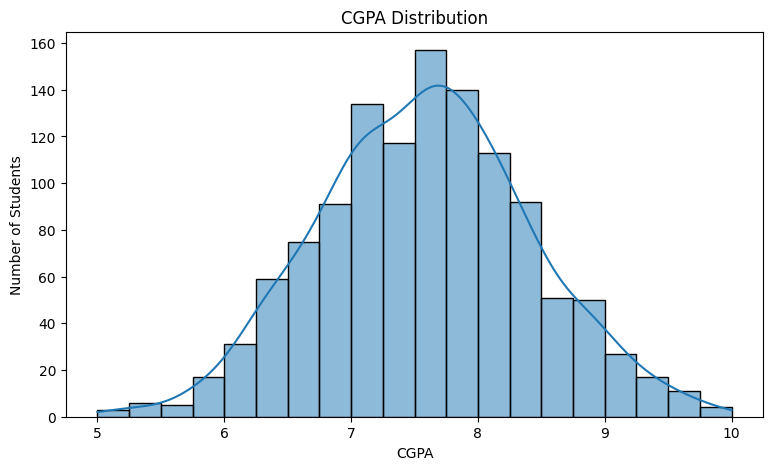

In [ ]:
plt.figure(figsize=(9,5))

sns.histplot(
    df["CGPA"],
    bins=20,
    kde=True
)

plt.title("CGPA Distribution")

plt.xlabel("CGPA")
plt.ylabel("Number of Students")

plt.show()

CGPA vs Placement

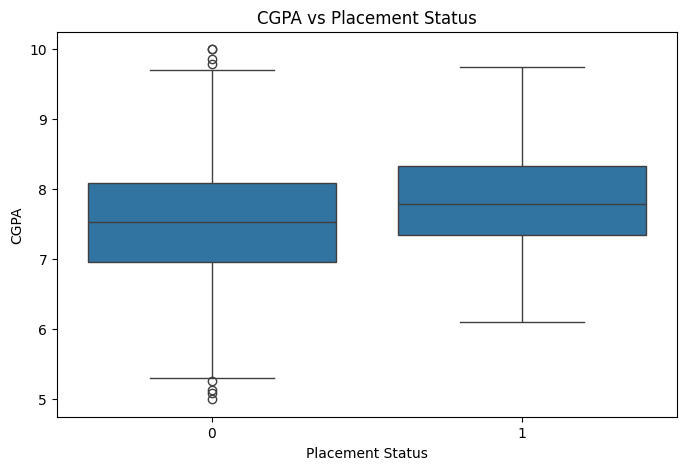

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Placement_Status",
    y="CGPA"
)

plt.title("CGPA vs Placement Status")

plt.xlabel("Placement Status")
plt.ylabel("CGPA")

plt.show()

##PART C — SKILL GAP ANALYSIS

Average Skill Scores

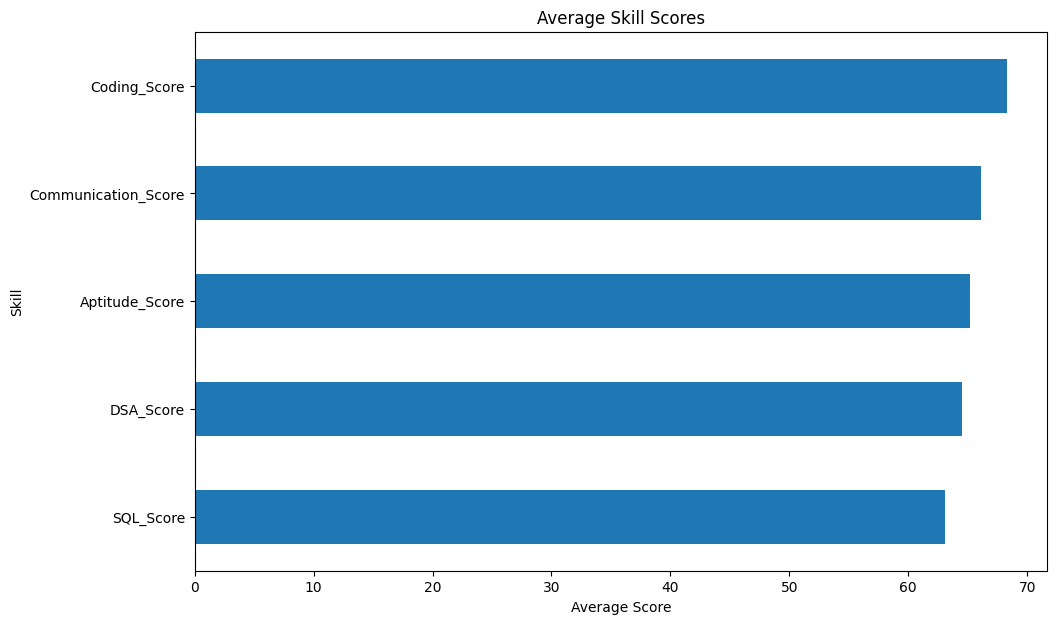

In [ ]:
skill_columns = [
    "Coding_Score",
    "Aptitude_Score",
    "Communication_Score",
    "Technical_Score",
    "DSA_Score",
    "SQL_Score",
    "Python_Score",
    "Java_Score",
    "Web_Development_Score",
    "ML_Score",
    "Soft_Skills_Score",
    "Resume_Score"
]

# Filter the list to only include columns that actually exist in the DataFrame
existing_skill_columns = [col for col in skill_columns if col in df.columns]

skill_average = df[existing_skill_columns].mean().sort_values()

plt.figure(figsize=(11,7))

skill_average.plot(
    kind="barh"
)

plt.title("Average Skill Scores")

plt.xlabel("Average Score")
plt.ylabel("Skill")

plt.show()

Skill Gap Level Distribution

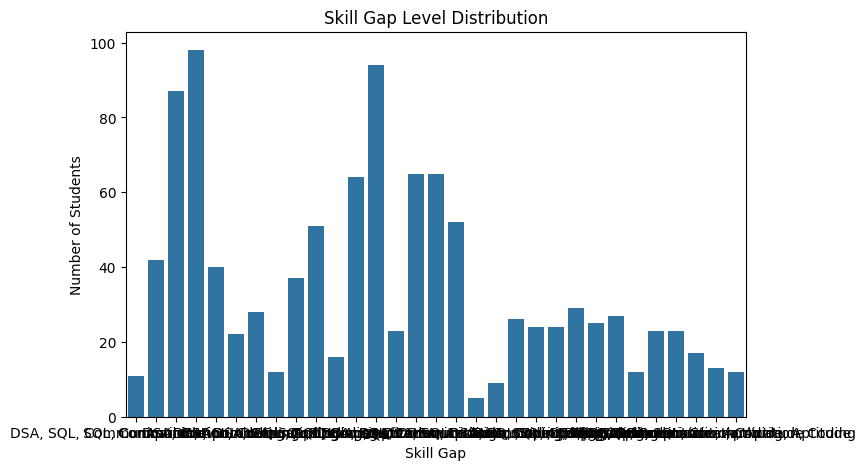

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Skill_Gap"
)

plt.title("Skill Gap Level Distribution")

plt.xlabel("Skill Gap")
plt.ylabel("Number of Students")

plt.show()

Skill Average vs Placement

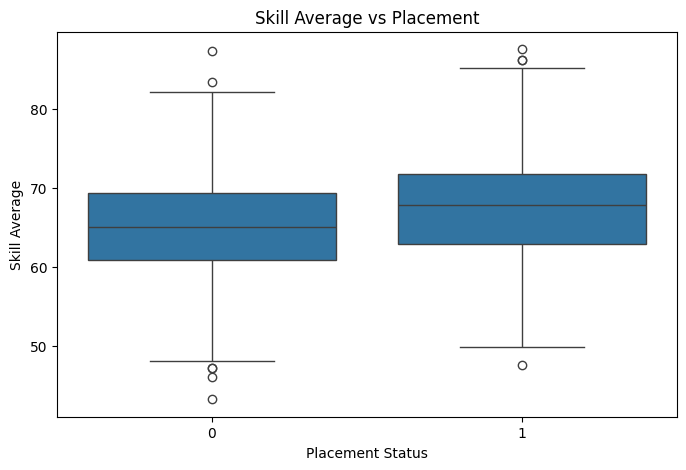

In [ ]:
plt.figure(figsize=(8,5))

# Identify skill columns that are actually present in the dataframe
existing_skills = [col for col in [
    "Coding_Score", "Aptitude_Score", "Communication_Score",
    "DSA_Score", "SQL_Score", "Technical_Score", "Python_Score",
    "Java_Score", "Web_Development_Score", "ML_Score",
    "Soft_Skills_Score", "Resume_Score"
] if col in df.columns]

# Calculate row-wise average of these existing skills
df["Skill_Average"] = df[existing_skills].mean(axis=1)

sns.boxplot(
    data=df,
    x="Placement_Status",
    y="Skill_Average"
)

plt.title("Skill Average vs Placement")

plt.xlabel("Placement Status")
plt.ylabel("Skill Average")

plt.show()

Internship vs Placement

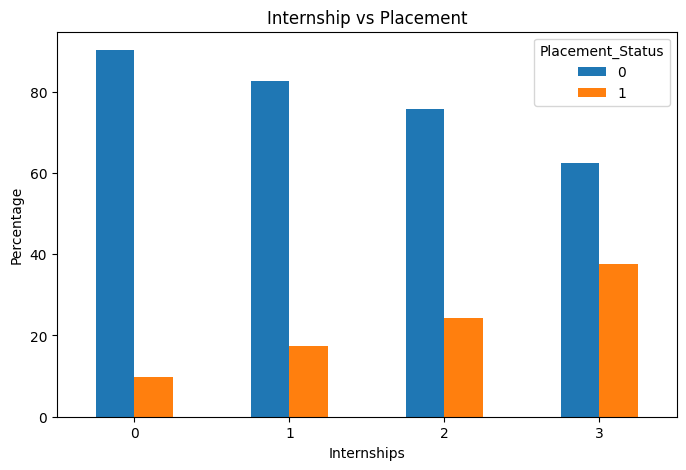

In [ ]:
intern_data = pd.crosstab(
    df["Internships"],
    df["Placement_Status"],
    normalize="index"
) * 100

intern_data.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Internship vs Placement")

plt.xlabel("Internships")

plt.ylabel("Percentage")

plt.xticks(rotation=0)

plt.show()

##PART D — CORRELATION ANALYSIS

Correlation Heatmap

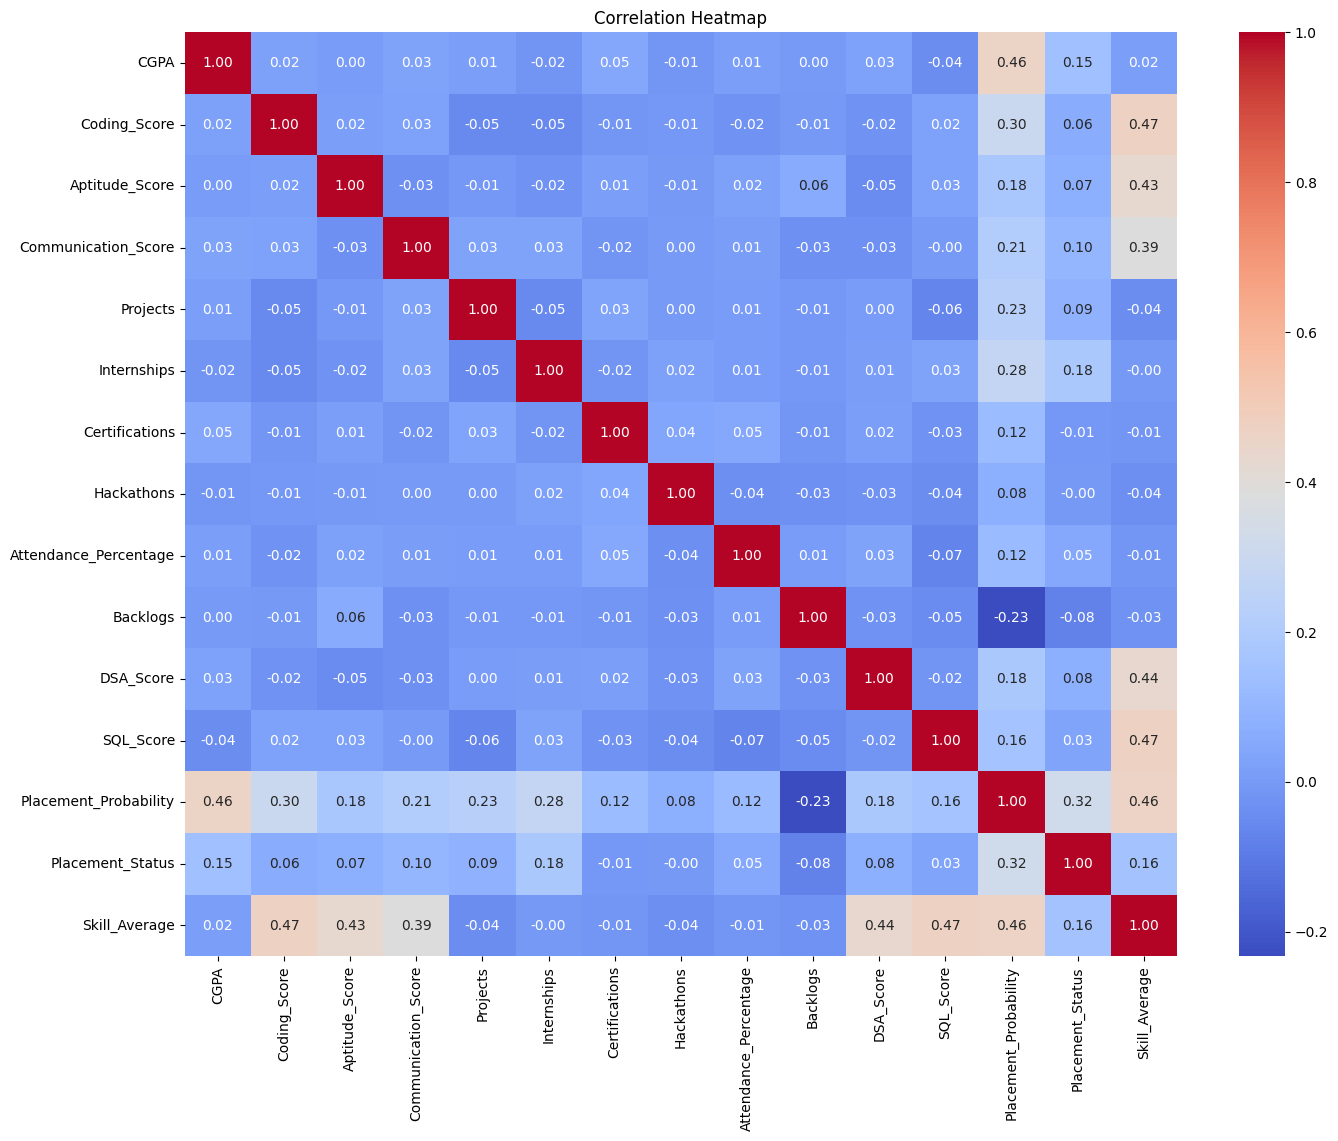

In [ ]:
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
)

correlation = numeric_columns.corr()

plt.figure(figsize=(16,12))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

##PART E — PREPROCESSING PIPELINE

Identify categorical and numerical columns

In [ ]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical:")
print(categorical_features)

print("\nNumerical:")
print(numerical_features)

Categorical:
['Skill_Gap', 'Recommendation']

Numerical:
['CGPA', 'Coding_Score', 'Aptitude_Score', 'Communication_Score', 'Projects', 'Internships', 'Certifications', 'Hackathons', 'Attendance_Percentage', 'Backlogs', 'DSA_Score', 'SQL_Score', 'Placement_Probability']


Create preprocessing pipeline

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "numerical",
        numeric_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

Train-test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (960, 15)
Testing: (240, 15)


##PART F — MACHINE LEARNING MODELS

Define ML models

In [ ]:
models = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "KNN":
        KNeighborsClassifier(n_neighbors=5),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=6,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ),

    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=200,
            random_state=42
        ),

    "Gradient Boosting":
        GradientBoostingClassifier(
            n_estimators=100,
            random_state=42
        ),

    "AdaBoost":
        AdaBoostClassifier(
            n_estimators=100,
            random_state=42
        ),

    "Naive Bayes":
        GaussianNB(),

    "SVM":
        SVC(
            probability=True,
            random_state=42
        ),

    "XGBoost":
        XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            eval_metric="logloss"
        ),

    "LightGBM":
        LGBMClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            verbosity=-1
        )
}

Train all models

In [ ]:
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(
        X_train,
        y_train
    )

    y_pred = pipeline.predict(X_test)

    y_probability = pipeline.predict_proba(
        X_test
    )[:, 1]

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred
    )

    recall = recall_score(
        y_test,
        y_pred
    )

    f1 = f1_score(
        y_test,
        y_pred
    )

    auc = roc_auc_score(
        y_test,
        y_probability
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        auc
    ])

    trained_models[name] = pipeline

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


PART G — MODEL COMPARISON

Create results table

In [ ]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "ROC_AUC"
    ]
)

results_df = results_df.sort_values(
    "Accuracy",
    ascending=False
)

display(
    results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
9,XGBoost,0.8667,0.8571,0.1622,0.2727,0.6372
1,KNN,0.8583,0.6364,0.1892,0.2917,0.6314
0,Logistic Regression,0.8583,0.7143,0.1351,0.2273,0.7520
10,LightGBM,0.8542,0.6250,0.1351,0.2222,0.6471
3,Random Forest,0.8542,1.0000,0.0541,0.1026,0.6916
4,Extra Trees,0.8542,1.0000,0.0541,0.1026,0.6981
6,AdaBoost,0.8500,0.5556,0.1351,0.2174,0.7328
5,Gradient Boosting,0.8500,0.5714,0.1081,0.1818,0.6485
8,SVM,0.8458,0.0000,0.0000,0.0000,0.6380
2,Decision Tree,0.8333,0.3846,0.1351,0.2000,0.5657


Accuracy Graph

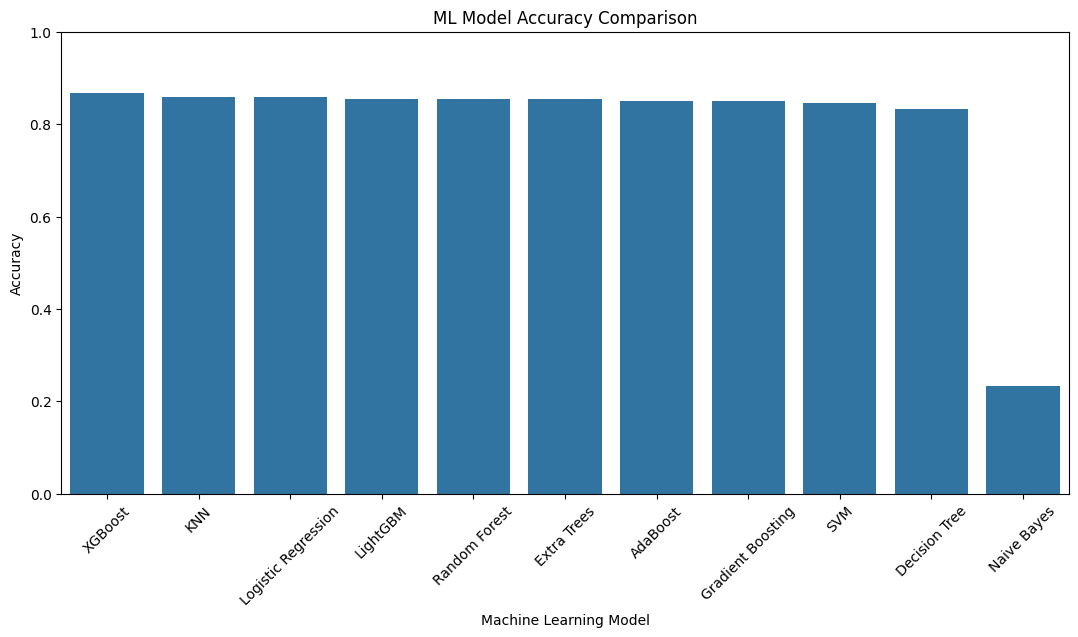

In [ ]:
plt.figure(figsize=(13,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("ML Model Accuracy Comparison")

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=45)

plt.ylim(0,1)

plt.show()

Precision, Recall and F1 Graph

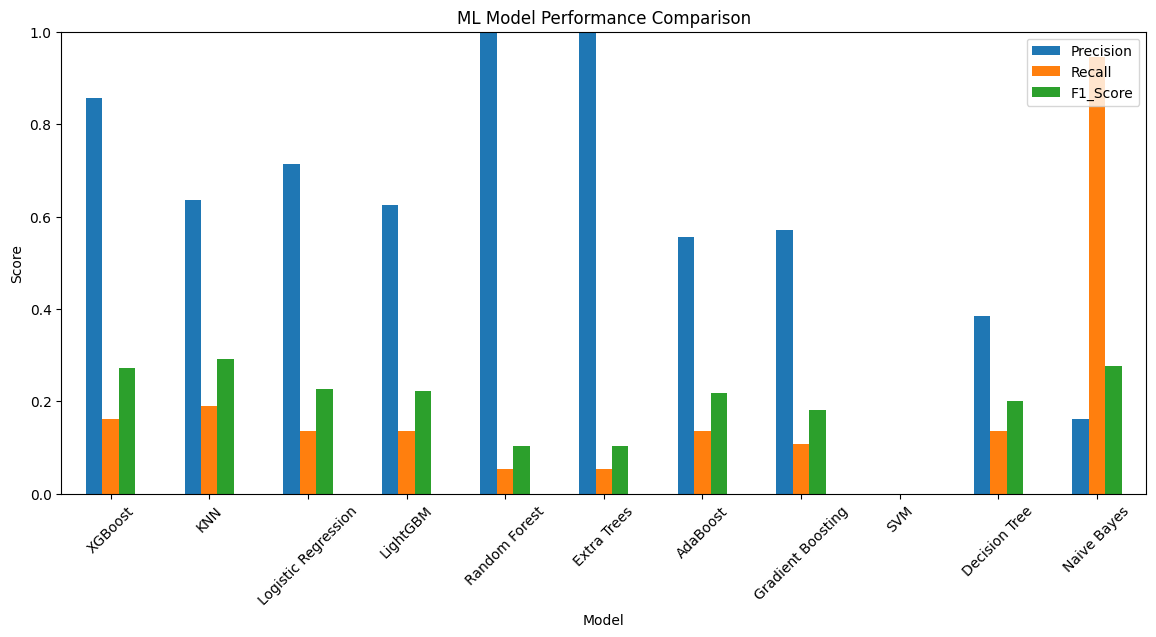

In [ ]:
performance = results_df.set_index(
    "Model"
)[
    ["Precision", "Recall", "F1_Score"]
]

performance.plot(
    kind="bar",
    figsize=(14,6)
)

plt.title(
    "ML Model Performance Comparison"
)

plt.xlabel("Model")
plt.ylabel("Score")

plt.xticks(rotation=45)

plt.ylim(0,1)

plt.show()

ROC-AUC Graph

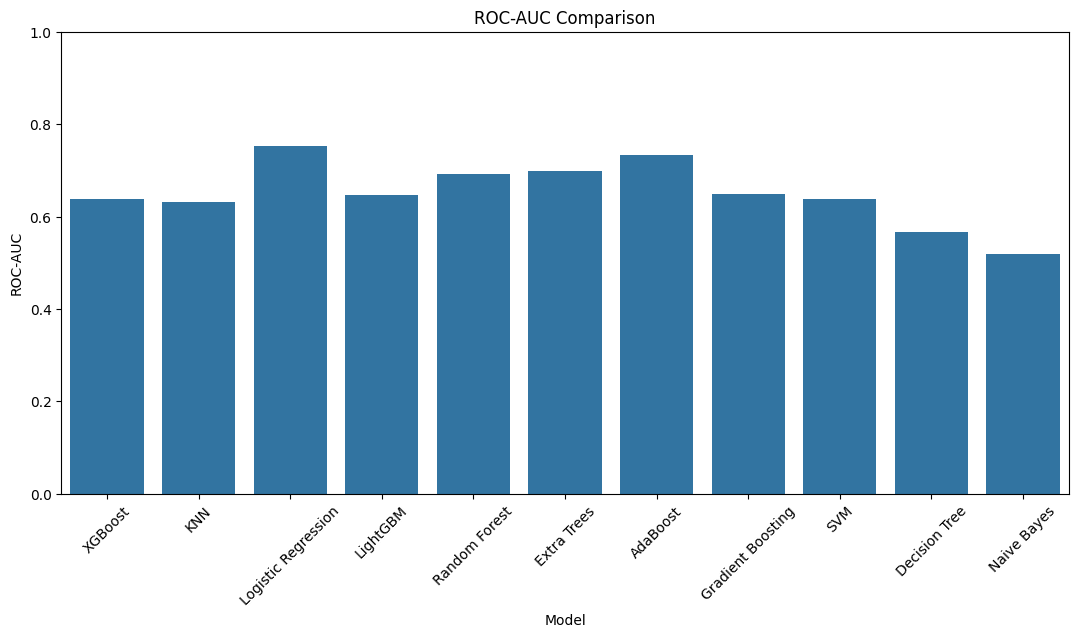

In [ ]:
plt.figure(figsize=(13,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC_AUC"
)

plt.title("ROC-AUC Comparison")

plt.xlabel("Model")
plt.ylabel("ROC-AUC")

plt.xticks(rotation=45)

plt.ylim(0,1)

plt.show()

##PART H — CONFUSION MATRIX

Confusion matrices for important models

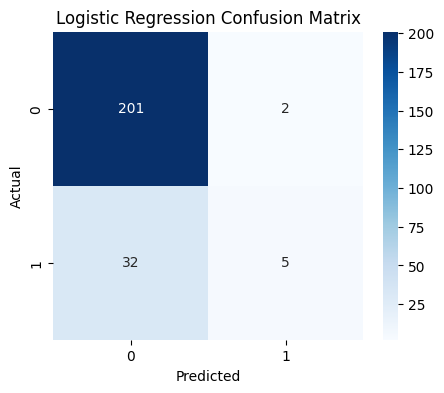

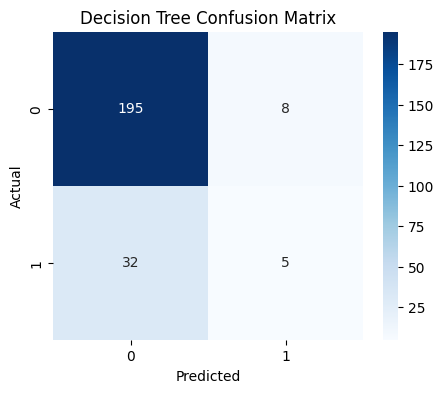

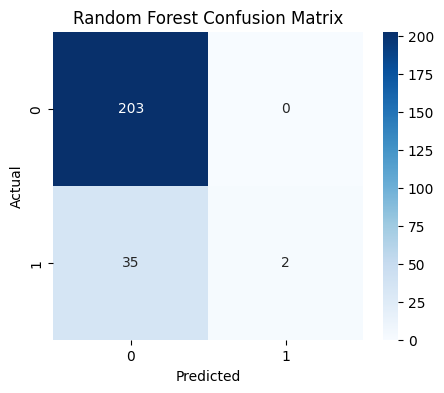

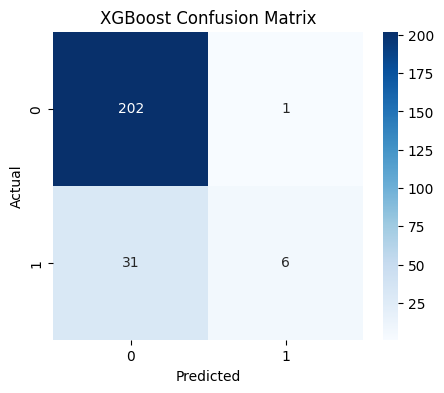

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


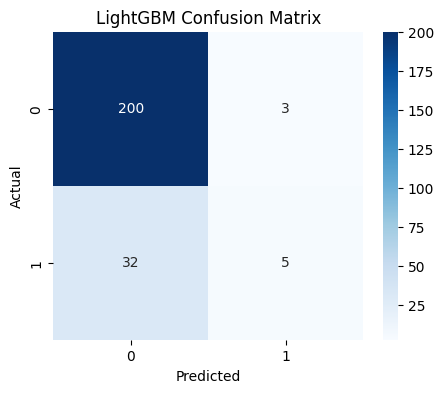

In [ ]:
important_models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "LightGBM"
]

for name in important_models:

    model = trained_models[name]

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions
    )

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(
        name + " Confusion Matrix"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

##PART I — ROC CURVES

ROC Curve for all models

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


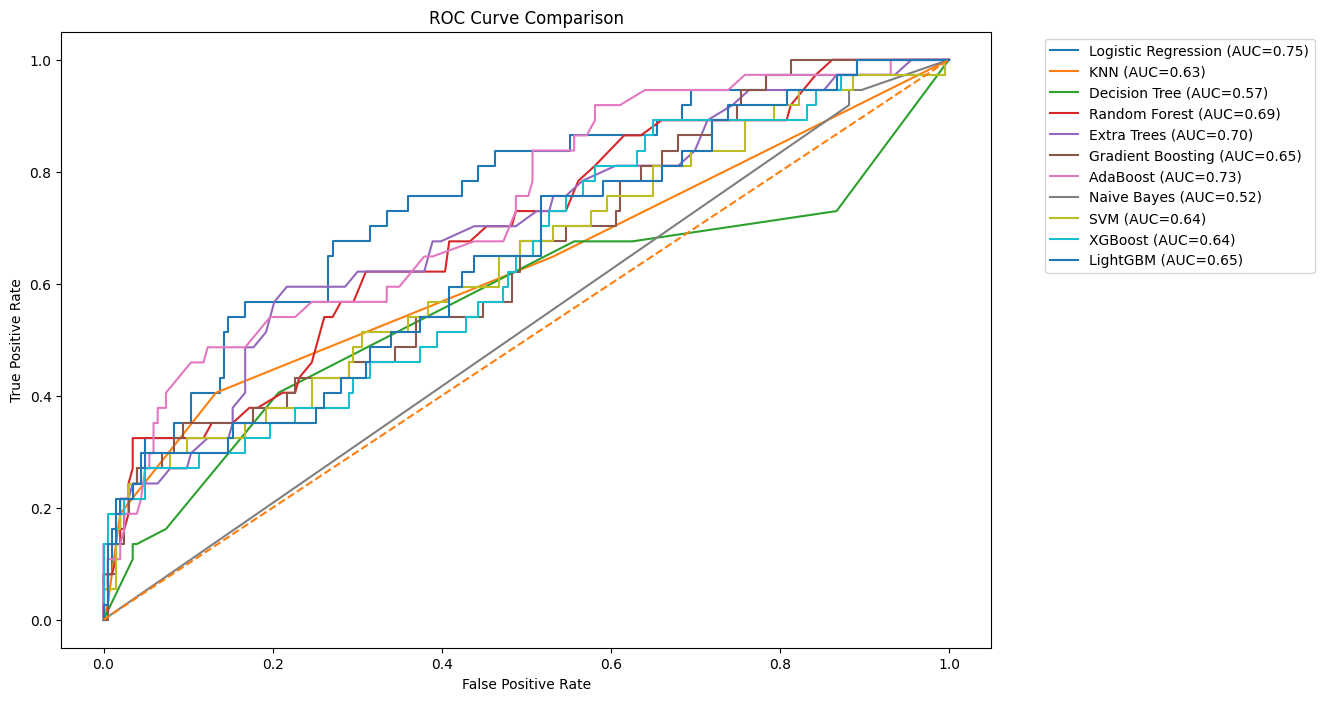

In [ ]:
plt.figure(figsize=(12,8))

for name, model in trained_models.items():

    probability = model.predict_proba(
        X_test
    )[:,1]

    fpr, tpr, _ = roc_curve(
        y_test,
        probability
    )

    auc = roc_auc_score(
        y_test,
        probability
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.2f})"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend(
    bbox_to_anchor=(1.05,1),
    loc="upper left"
)

plt.show()

##PART J — RANDOM FOREST FEATURE IMPORTANCE

Feature importance

In [ ]:
rf_pipeline = trained_models[
    "Random Forest"
]

rf_model = rf_pipeline.named_steps[
    "model"
]

preprocess = rf_pipeline.named_steps[
    "preprocessing"
]

feature_names = (
    preprocess
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(
    importance.head(20)
)

,Feature,Importance
12,numerical__Placement_Probability,0.131885
0,numerical__CGPA,0.086340
10,numerical__DSA_Score,0.085059
3,numerical__Communication_Score,0.072758
11,numerical__SQL_Score,0.071642
2,numerical__Aptitude_Score,0.069955
1,numerical__Coding_Score,0.069352
8,numerical__Attendance_Percentage,0.067568
4,numerical__Projects,0.048534
5,numerical__Internships,0.042077


Feature importance graph

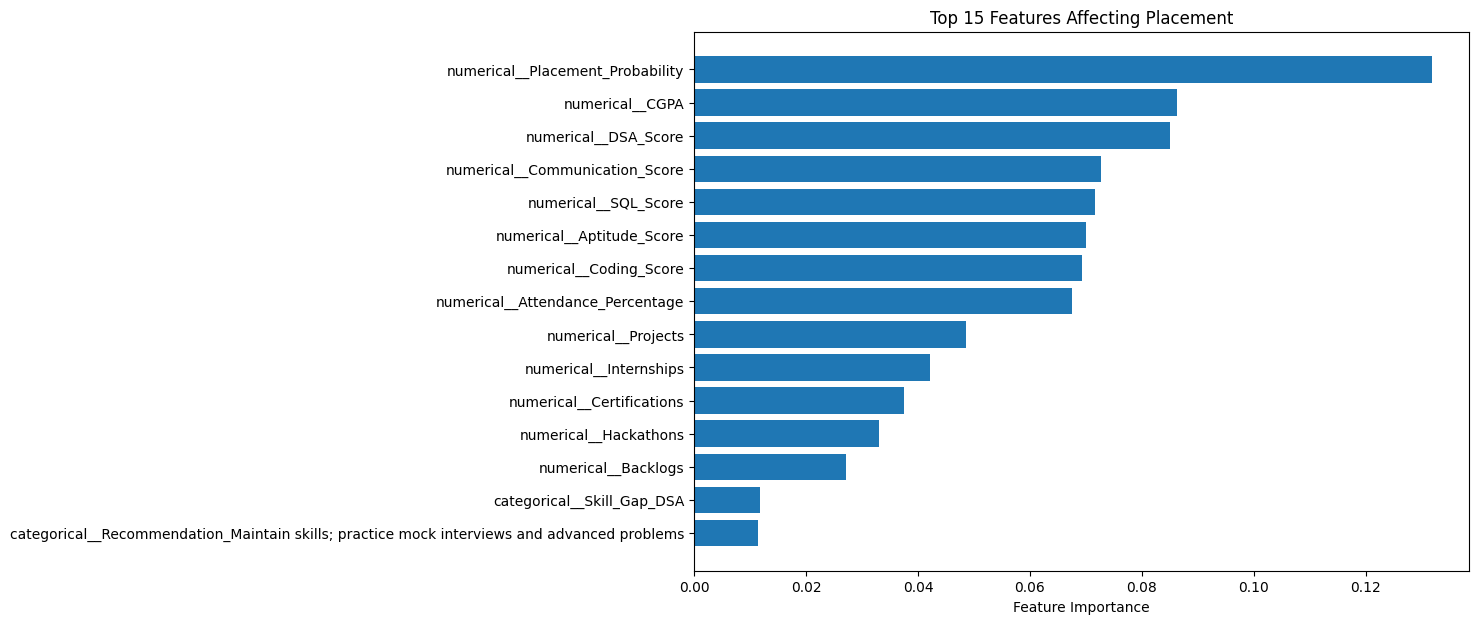

In [ ]:
top_features = importance.head(15)

plt.figure(figsize=(10,7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title(
    "Top 15 Features Affecting Placement"
)

plt.xlabel("Feature Importance")

plt.gca().invert_yaxis()

plt.show()

##PART K — DEEP LEARNING MODEL

Prepare data for ANN

In [ ]:
# Transform the training and testing features using our fitted preprocessor pipeline
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert targets to numpy arrays for compatibility with TensorFlow/Keras
y_train_arr = np.array(y_train)
y_test_arr = np.array(y_test)

print("Processed Training Features Shape:", X_train_processed.shape)
print("Processed Testing Features Shape:", X_test_processed.shape)

Processed Training Features Shape: (960, 76)
Processed Testing Features Shape: (240, 76)
